# Meteosat-12 (MTG-FCI) Data Retrieval & Inspection

Questo notebook mostra come:
1. Autenticarsi su **EUMETSAT Data Store** con `eumdac` usando **Colab Secrets**.
2. Elencare le collezioni **MTG-FCI** disponibili.
3. Cercare e scaricare una scena di prova su un incendio europeo (usando coordinate/date da **Copernicus EMS**, es. `https://mapping.emergency.copernicus.eu/activations/EMSR921/`).
4. Aprirla con `satpy`, ritagliare la bounding box e ispezionare i canali spettrali.

### Setup credenziali su Colab (`eumdac >= 4.0.0`, OAuth2 v2)
Nella barra sinistra di Colab, clicca l'icona della **chiave (Secrets)** e aggiungi le tue credenziali dello **User Portal EUMETSAT** (non più Consumer Key/Secret):
- `EUMDAC_USER` (il tuo username, es. `pippo03`)
- `EUMDAC_PW` (la tua password EUMETSAT)
*(Ricorda di attivare lo switch **Notebook access** per entrambi.)*

In [4]:
%pip install -q --upgrade "eumdac>=4.0.0" satpy netCDF4 pyyaml tifffile

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [5]:
import os
import shutil
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import eumdac
import matplotlib.pyplot as plt
import numpy as np

from eumdac.datastore import DataStore
from eumdac.token import Creds, OAuth2Token

try:
    from google.colab import userdata
    EUMDAC_USER = userdata.get("EUMDAC_USER")
    EUMDAC_PW = userdata.get("EUMDAC_PW")
except Exception:
    EUMDAC_USER = os.getenv("EUMDAC_USER")
    EUMDAC_PW = os.getenv("EUMDAC_PW")

assert EUMDAC_USER and EUMDAC_PW, "Imposta EUMDAC_USER e EUMDAC_PW nei Colab Secrets!"

creds = Creds(user=EUMDAC_USER, pw=EUMDAC_PW)
token = OAuth2Token().set_credentials(creds)
datastore = DataStore(token)
print("Autenticazione EUMETSAT v2 riuscita!")

Autenticazione EUMETSAT v2 riuscita!


In [6]:
# 1) Verifica collezioni MTG / FCI disponibili
fci_collections = []
for coll in datastore.collections:
    title = getattr(coll, "title", "") or ""
    if "FCI" in str(coll).upper() or "FCI" in title.upper() or "MTG" in title.upper():
        fci_collections.append((str(coll), title))
        print(f"{coll}  -->  {title}")

EO:EUM:DAT:0737  -->  IRS Level 1 reduced sub-set of 300 Principal Components - MTG
EO:EUM:DAT:0741  -->  IRS Level 1 spectral soundings - MTG
EO:EUM:DAT:0799  -->  All Sky Radiance (BUFR) - MTG - 0 degree
EO:EUM:DAT:0998  -->  Atmospheric Motion Vectors (BUFR) - MTG - 0 degree
EO:EUM:DAT:0782  -->  LI Lightning Groups - MTG - 0 degree
EO:EUM:DAT:0801  -->  Active Fire Monitoring (CAP) - MTG - 0 degree
EO:EUM:DAT:0800  -->  Cloud Mask (GRIB2) - MTG - 0 degree
EO:EUM:DAT:0676  -->  Atmospheric Motion Vectors (netCDF) - MTG - 0 degree
EO:EUM:DAT:0678  -->  Cloud Mask (netCDF) - MTG - 0 degree
EO:EUM:DAT:0677  -->  All Sky Radiance (netCDF) - MTG - 0 degree
EO:EUM:DAT:0679  -->  Clear Sky Reflectance Map - MTG - 0 degree
EO:EUM:DAT:0683  -->  Global Instability Indices - MTG - 0 degree
EO:EUM:DAT:0682  -->  Active Fire Monitoring (netCDF) - MTG - 0 degree
EO:EUM:DAT:0685  -->  Outgoing LW radiation at TOA - MTG - 0 degree
EO:EUM:DAT:0684  -->  Optimal Cloud Analysis - MTG - 0 degree
EO:EU

In [7]:
# 2) Ricerca di prova su MTG-FCI Level 1c Normal Resolution (FDHSI: EO:EUM:DAT:0662)
COLLECTION_ID = "EO:EUM:DAT:0662"
collection = datastore.get_collection(COLLECTION_ID)

# Finestra temporale e bounding box di esempio: Copernicus EMSR921 (Wildfire in Aragon, Spain - 15 agosto 2026)
# Nota: l'archivio EO:EUM:DAT:0662 parte dal 23 settembre 2024; per i Full Disc cerchiamo per data/ora e ritagliamo poi con Satpy.
start = datetime(2026, 8, 15, 12, 0, tzinfo=timezone.utc)
end = datetime(2026, 8, 15, 12, 30, tzinfo=timezone.utc)
west, south, east, north = -2.5, 39.8, 0.8, 42.9  # Aragon, Spain (EMSR921)

products = list(collection.search(dtstart=start, dtend=end))
print(f"Prodotti trovati: {len(products)}")
for p in products[:5]:
    print(" -", p)

Prodotti trovati: 3
 - W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260815122328_IDPFI_OPE_20260815122007_20260815122935_N__O_0075_0000
 - W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260815121319_IDPFI_OPE_20260815121007_20260815121935_N__O_0074_0000
 - W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260815120318_IDPFI_OPE_20260815120007_20260815120935_N__O_0073_0000


In [8]:
# 3) Scarica ed estrai il primo prodotto (attenzione: un Full Disc pesa diverse centinaia di MB)
assert len(products) > 0, "Nessun prodotto trovato nella finestra selezionata."

OUT_DIR = Path("./eumetsat_sample")
OUT_DIR.mkdir(parents=True, exist_ok=True)

product = products[0]
zip_path = OUT_DIR / f"{product}.zip"
if not zip_path.exists():
    print("Downloading:", product)
    with product.open() as src, open(zip_path, "wb") as dst:
        shutil.copyfileobj(src, dst)
print("File salvato:", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")

extract_dir = zip_path.with_suffix("")
if not extract_dir.exists():
    extract_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)

nc_files = sorted(str(p) for p in extract_dir.rglob("*.nc") if "CHK-TRAIL" not in p.name)
print(f"File NetCDF estratti: {len(nc_files)}")

Downloading: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260815122328_IDPFI_OPE_20260815122007_20260815122935_N__O_0075_0000
File salvato: eumetsat_sample/W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260815122328_IDPFI_OPE_20260815122007_20260815122935_N__O_0075_0000.zip (1041.5 MB)
File NetCDF estratti: 40


In [9]:
# 4) Lettura con Satpy, ispezione canali e ritaglio sulla bounding box
import dask
from satpy import Scene

nc_files_body = [f for f in nc_files if "CHK-TRAIL" not in f]
scn = Scene(filenames=nc_files_body, reader="fci_l1c_nc")
available = sorted(scn.available_dataset_names())
print("Canali principali in FCI L1c:", [c for c in available if not any(s in c for s in ("_",)) or len(c) <= 6])

# Carichiamo i canali principali VIS / NIR / IR (per confronto con GOES-16 ABI)
target_channels = [c for c in ["vis_06", "vis_05", "vis_04", "vis_08", "nir_16", "nir_22", "ir_38", "ir_105", "ir_123"] if c in available]
scn.load(target_channels)

cropped = scn.crop(ll_bbox=(west, south, east, north))
resampled = cropped.resample(cropped.finest_area(), resampler="nearest")

with dask.config.set(scheduler="synchronous"):
    for ch in target_channels:
        arr = np.asarray(resampled[ch].values, dtype=np.float32)
        print(f"{ch:8s} | shape={arr.shape} | min={np.nanmin(arr):.3f} | max={np.nanmax(arr):.3f}")

Canali principali in FCI L1c: ['ir_105', 'ir_123', 'ir_133', 'ir_38', 'ir_87', 'ir_97', 'nir_13', 'nir_16', 'nir_22', 'vis_04', 'vis_05', 'vis_06', 'vis_08', 'vis_09', 'wv_63', 'wv_73']
vis_06   | shape=(222, 272) | min=4.800 | max=106.182
vis_05   | shape=(222, 272) | min=10.190 | max=107.538
vis_04   | shape=(222, 272) | min=13.738 | max=106.599
vis_08   | shape=(222, 272) | min=2.748 | max=114.320
nir_16   | shape=(222, 272) | min=1.130 | max=66.835
nir_22   | shape=(222, 272) | min=0.319 | max=55.357
ir_38    | shape=(222, 272) | min=250.944 | max=318.996
ir_105   | shape=(222, 272) | min=217.392 | max=306.045
ir_123   | shape=(222, 272) | min=216.932 | max=299.201


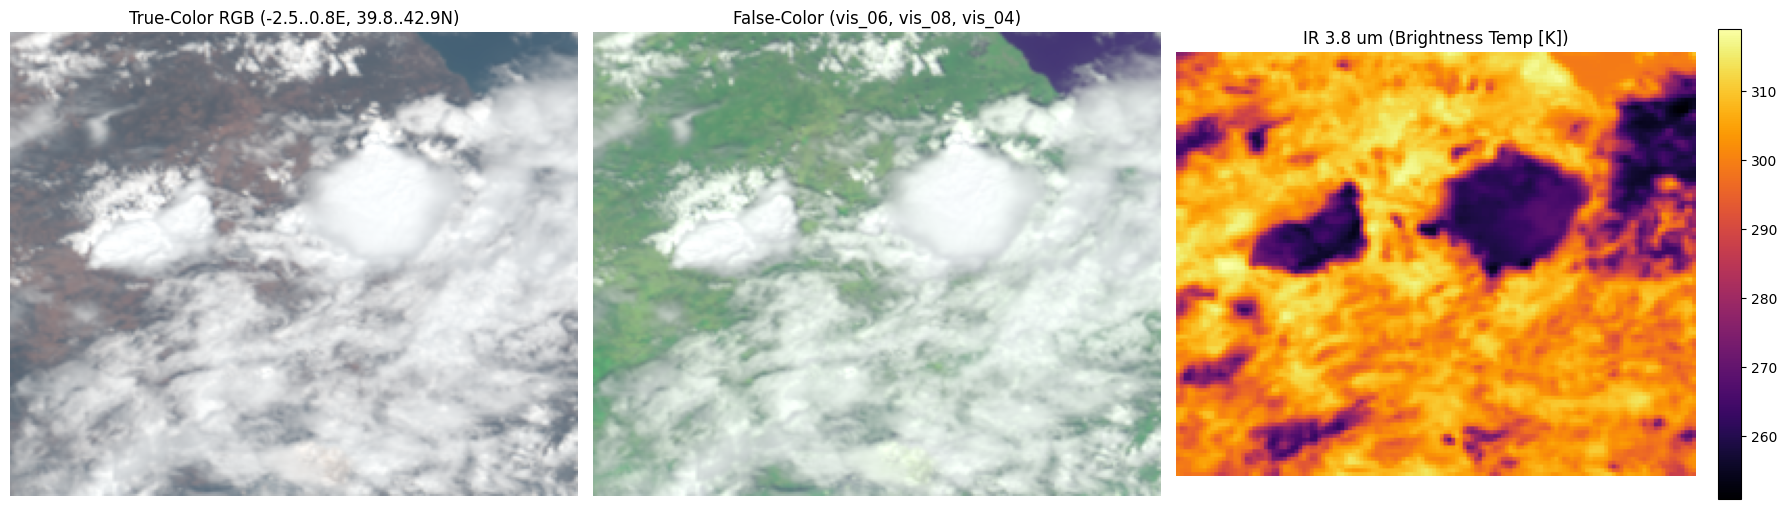

In [10]:
# 5) Visualizzazione 3 pannelli: True-Color RGB, False-Color (con vis_08) e IR 3.8 um
if all(c in target_channels for c in ["vis_06", "vis_05", "vis_04", "vis_08"]):
    with dask.config.set(scheduler="synchronous"):
        r = np.asarray(resampled["vis_06"].values, dtype=np.float32)
        g_true = np.asarray(resampled["vis_05"].values, dtype=np.float32)
        g_false = np.asarray(resampled["vis_08"].values, dtype=np.float32)
        b = np.asarray(resampled["vis_04"].values, dtype=np.float32)
        ir38 = np.asarray(resampled["ir_38"].values, dtype=np.float32) if "ir_38" in target_channels else None

    def norm_rgb(stack):
        out = np.clip(stack / (np.nanpercentile(stack, 99) + 1e-6), 0, 1)
        return np.power(out, 1.0 / 2.2)

    rgb_true = norm_rgb(np.stack([r, g_true, b], axis=-1))
    rgb_false = norm_rgb(np.stack([r, g_false, b], axis=-1))

    ncols = 3 if ir38 is not None else 2
    fig, axes = plt.subplots(1, ncols, figsize=(6 * ncols, 5))
    axes[0].imshow(rgb_true)
    axes[0].set_title(f"True-Color RGB ({west}..{east}E, {south}..{north}N)")
    axes[0].axis("off")

    axes[1].imshow(rgb_false)
    axes[1].set_title("False-Color (vis_06, vis_08, vis_04)")
    axes[1].axis("off")

    if ir38 is not None:
        im = axes[2].imshow(ir38, cmap="inferno")
        axes[2].set_title("IR 3.8 um (Brightness Temp [K])")
        axes[2].axis("off")
        plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

Scarico 2026-08-11 09:00 UTC...
  chunk .nc trovati: 40
Scarico 2026-08-11 11:00 UTC...
  chunk .nc trovati: 40
2026-08-12 09:00:00+00:00: nessun prodotto
Scarico 2026-08-12 11:00 UTC...
  chunk .nc trovati: 40


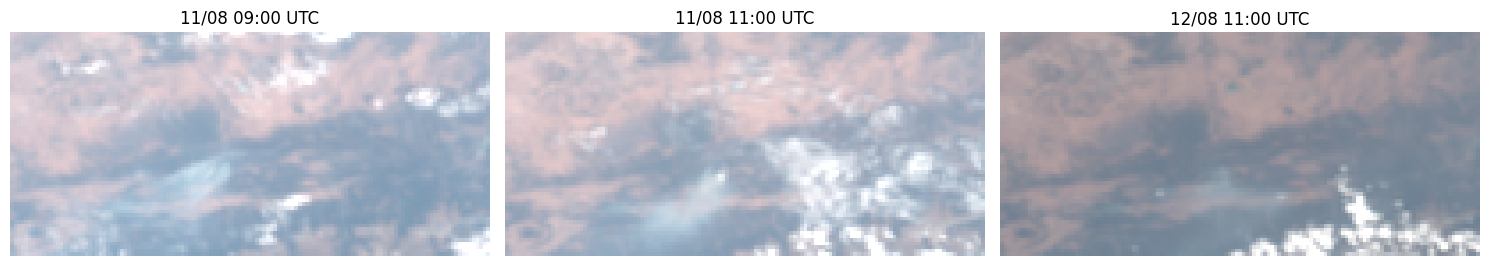

In [14]:
import dask
from satpy import Scene
from datetime import timedelta

west, south, east, north = -1.5, 41.9, 0.2, 42.8  # Crop stretto su Jaca / Riglos
timestamps = [
    datetime(2026, 8, 11, 9, 0, tzinfo=timezone.utc),
    datetime(2026, 8, 11, 11, 0, tzinfo=timezone.utc),
    datetime(2026, 8, 12, 9, 0, tzinfo=timezone.utc),
    datetime(2026, 8, 12, 11, 0, tzinfo=timezone.utc),
]

crops = []
TMP_DIR = Path("./eumetsat_tmp")
TMP_DIR.mkdir(exist_ok=True)

for ts in timestamps:
    prods = list(collection.search(dtstart=ts, dtend=ts + timedelta(minutes=15)))
    if not prods:
        print(f"{ts}: nessun prodotto")
        continue

    prod = prods[0]
    zip_p = TMP_DIR / f"{prod}.zip"
    ext_p = TMP_DIR / str(prod)

    try:
        print(f"Scarico {ts:%Y-%m-%d %H:%M UTC}...")
        with prod.open() as src, open(zip_p, "wb") as dst:
            shutil.copyfileobj(src, dst)

        with zipfile.ZipFile(zip_p, "r") as zf:
            zf.extractall(ext_p)

        nc_body = sorted(str(p) for p in ext_p.rglob("*.nc") if "CHK-TRAIL" not in p.name)
        print(f"  chunk .nc trovati: {len(nc_body)}")

        scn = Scene(filenames=nc_body, reader="fci_l1c_nc")
        scn.load(["vis_06", "vis_05", "vis_04"])
        cropped = scn.crop(ll_bbox=(west, south, east, north))
        res = cropped.resample(cropped.finest_area(), resampler="nearest")

        with dask.config.set(scheduler="synchronous"):
            r = np.asarray(res["vis_06"].values, dtype=np.float32)
            g = np.asarray(res["vis_05"].values, dtype=np.float32)
            b = np.asarray(res["vis_04"].values, dtype=np.float32)

        rgb = np.stack([r, g, b], axis=-1)
        rgb = np.clip(rgb / (np.nanpercentile(rgb, 99) + 1e-6), 0, 1)
        rgb = np.power(rgb, 1.0 / 2.2)
        crops.append((f"{ts:%d/%m %H:%M UTC}", rgb))
    except Exception as e:
        print(f"  Saltato {ts:%d/%m %H:%M UTC} per errore: {type(e).__name__}: {e}")
    finally:
        zip_p.unlink(missing_ok=True)
        shutil.rmtree(ext_p, ignore_errors=True)

if crops:
    fig, axes = plt.subplots(1, len(crops), figsize=(5 * len(crops), 5))
    if len(crops) == 1:
        axes = [axes]
    for ax, (label, img) in zip(axes, crops):
        ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Shape del crop MTG-FCI: (154, 201, 3)


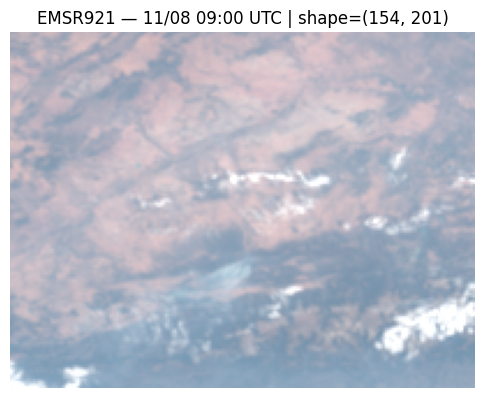

In [15]:
west, south, east, north = -2.0, 41.0, 0.5, 43.2  # ~2.5° x 2.2° centrata sull'Aragona
ts = datetime(2026, 8, 11, 9, 0, tzinfo=timezone.utc)

prods = list(collection.search(dtstart=ts, dtend=ts + timedelta(minutes=15)))
prod = prods[0]
zip_p = TMP_DIR / f"{prod}.zip"
ext_p = TMP_DIR / str(prod)

try:
    with prod.open() as src, open(zip_p, "wb") as dst:
        shutil.copyfileobj(src, dst)
    with zipfile.ZipFile(zip_p, "r") as zf:
        zf.extractall(ext_p)

    nc_body = sorted(str(p) for p in ext_p.rglob("*.nc") if "CHK-TRAIL" not in p.name)
    scn = Scene(filenames=nc_body, reader="fci_l1c_nc")
    scn.load(["vis_06", "vis_05", "vis_04"])
    cropped = scn.crop(ll_bbox=(west, south, east, north))
    res = cropped.resample(cropped.finest_area(), resampler="nearest")

    with dask.config.set(scheduler="synchronous"):
        r = np.asarray(res["vis_06"].values, dtype=np.float32)
        g = np.asarray(res["vis_05"].values, dtype=np.float32)
        b = np.asarray(res["vis_04"].values, dtype=np.float32)

    rgb = np.stack([r, g, b], axis=-1)
    rgb = np.clip(rgb / (np.nanpercentile(rgb, 99) + 1e-6), 0, 1)
    rgb = np.power(rgb, 1.0 / 2.2)

    print("Shape del crop MTG-FCI:", rgb.shape)
    plt.figure(figsize=(6, 6))
    plt.imshow(rgb)
    plt.title(f"EMSR921 — 11/08 09:00 UTC | shape={rgb.shape[:2]}")
    plt.axis("off")
    plt.show()
finally:
    zip_p.unlink(missing_ok=True)
    shutil.rmtree(ext_p, ignore_errors=True)